<div style="background:#173f59;color:white;border-radius:7px;padding:23px 25px;">
<h1 style="color:white;margin:9px 0;font-size:28px;">What shapes rental costs in Marseille?</h1>
<p style="color:#e0eff5;font-size:14px;margin:8px 0 0;">five focused visual stories · Descriptive insights, affordability and adjusted comparisons</p>
</div>

This notebook summarizes selected findings from the separate EDA notebook. It does **not** repeat the full statistical tables or show a map. Each question is followed by one visualization and a short interpretation. 


<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">0 · Load and check the cleaned dataset</h2>

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">We load the analysis-ready CSV and keep the five zone names consistent throughout. No statistical output tables are reproduced here.</div>

In [8]:
from pathlib import Path
import shutil  # Create a ZIP archive of the exported charts.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from scipy.stats import norm
from IPython.display import display, HTML, FileLink

try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False


file_path = Path('marseille_cleaning_outputs/marseille_analysis_ready.csv')
if file_path is None:
    raise FileNotFoundError(
        'file not found.'
    )

# Create the output folder once. Re-running a chart cell updates its export.
CHARTS_DIR = Path('charts')
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

eda = pd.read_csv(file_path, low_memory=False)
required = ['urban_zone','property_type_label','surface_m2','price_total_eur',
            'price_per_m2','is_furnished_binary','dpe_class',
            'upfront_move_in_cost_eur','amenity_score','amenities_known_count']
absent = [col for col in required if col not in eda.columns]
if absent:
    raise ValueError(f'This is not the expected analysis-ready CSV. Missing: {absent}')

ZONE_SHORT = {
    '1. Littoral sud (7e, 8e)': 'Littoral Sud',
    '2. Sud et Est (6e, 9e, 12e)': 'Sud & Est',
    '3. Centre et Timone (1er, 4e, 5e)': 'Centre & Timone',
    '4. Euromed et Est (2e, 10e, 11e, 13e)': 'Euromed & Est',
    '5. Nord et 3e (3e, 14e, 15e, 16e)': 'Nord & 3e'
}
zones = list(ZONE_SHORT.keys())
zone_names = list(ZONE_SHORT.values())
zone_colors = ['#2c79a5','#db9355','#43a19a','#9881ad','#6589c3']
TYPE_ORDER = ['Studio / T1','T2','T3','T4+']
TYPE_COLORS = {'Studio / T1':'#2a9d8f','T2':'#467da6','T3':'#e6a166','T4+':'#9883b4'}
COLOR_FURNISHED = '#e59c58'
COLOR_UNFURNISHED = '#557b91'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'figure.facecolor':'white','axes.facecolor':'white'})
print(f'Loaded {len(eda)} advertisements from {file_path.name}.')
print(f'Chart exports will be saved in: {CHARTS_DIR.resolve()}')
print('Interactive notebook controls:', 'available' if HAS_WIDGETS else 'unavailable here — HTML versions are included')

Loaded 909 advertisements from marseille_analysis_ready.csv.
Chart exports will be saved in: C:\Users\romay\OneDrive\BOUKRIF_Romayssa_CHAHINE_Rami_G5\BOUKRIF_Romayssa_CHAHINE_Rami_G5_Code\charts
Interactive notebook controls: available


<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">PART I · Understand the advertised apartments</h2>

### 1 · Why small apartments cost more per square metre

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">We group apartments by surface and compare two different measures: total monthly rent and rent per square metre. The medians are calculated directly from the advertisements. The two panels use the same size categories.</div>

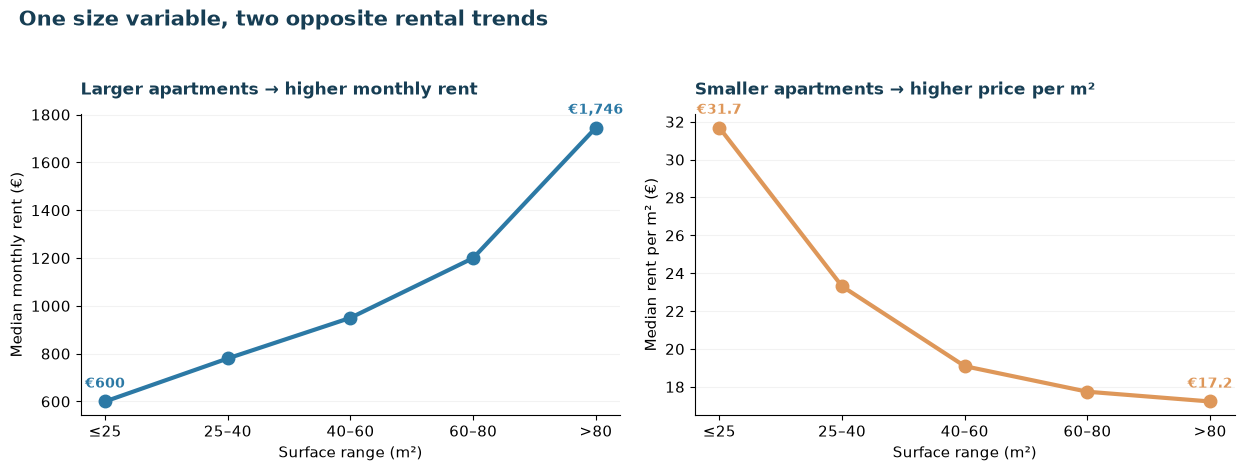

In [9]:
# Surface groups are ordered to highlight opposite price trends.
size_data = eda.dropna(subset=['surface_m2','price_total_eur','price_per_m2']).copy()
size_data = size_data.loc[(size_data['surface_m2'] > 0) &
                          (size_data['price_total_eur'] > 0) &
                          (size_data['price_per_m2'] > 0)]
# pd.cut converts continuous surfaces into ordered, interpretable ranges.
size_data['size_band'] = pd.cut(size_data['surface_m2'],
    bins=[0,25,40,60,80,np.inf],
    labels=['≤25','25–40','40–60','60–80','>80'], include_lowest=True)
# Use group medians to reduce the impact of unusually expensive listings.
size_summary = size_data.groupby('size_band', observed=True).agg(
    rent=('price_total_eur','median'),
    per_m2=('price_per_m2','median'), n=('price_total_eur','size'))

fig, ax = plt.subplots(1, 2, figsize=(12.6,4.5))
x = np.arange(len(size_summary))
for a,col,color,title,ylabel in [
    (ax[0],'rent','#2c79a5','Larger apartments → higher monthly rent','Median monthly rent (€)'),
    (ax[1],'per_m2','#de9759','Smaller apartments → higher price per m²','Median rent per m² (€)')]:
    values=size_summary[col].to_numpy()
    a.plot(x, values, marker='o', lw=3, ms=9, color=color)
    a.set_xticks(x, size_summary.index.astype(str))
    a.set_xlabel('Surface range (m²)'); a.set_ylabel(ylabel)
    a.set_title(title, loc='left', fontsize=12, color='#173e54', pad=14, weight='bold')
    a.grid(axis='y', alpha=.16); a.set_axisbelow(True)
    # Only label the endpoints, so the figure remains easy to read.
    for j in [0,len(values)-1]:
        label=f'€{values[j]:,.0f}' if col=='rent' else f'€{values[j]:.1f}'
        a.annotate(label, (x[j],values[j]), xytext=(0,10), textcoords='offset points',
                   ha='center',color=color,fontsize=10,weight='bold')
fig.suptitle('One size variable, two opposite rental trends', fontsize=15,
             color='#173e54', x=.02, ha='left', y=1.04, weight='bold')
fig.tight_layout()
# Save before showing; this avoids exporting a cleared or closed figure.
fig.savefig(CHARTS_DIR / '01_surface_vs_rent.png', dpi=300, bbox_inches='tight')
plt.show()

<div style="background:#edf8f2;border-left:4px solid #2b9a6c;padding:12px 15px;border-radius:5px;font-size:13px;color:#244838;line-height:1.55;"><strong style="color:#217d56;">Interpretation</strong><p style="margin:7px 0 0;">Across these listings, larger apartments have higher total rents, while the smallest apartments tend to have the highest prices per m². This difference matters for students seeking small homes. The chart describes an association, not a causal effect of surface alone.</p></div>

### 2 · Furnished apartments: smaller, yet pricier per m²

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">Within each geographical zone, we compare the median size and median price per m² of furnished and unfurnished listings. Orange always means furnished; blue means unfurnished. The connecting line is only a visual comparison, not a confidence interval.</div>

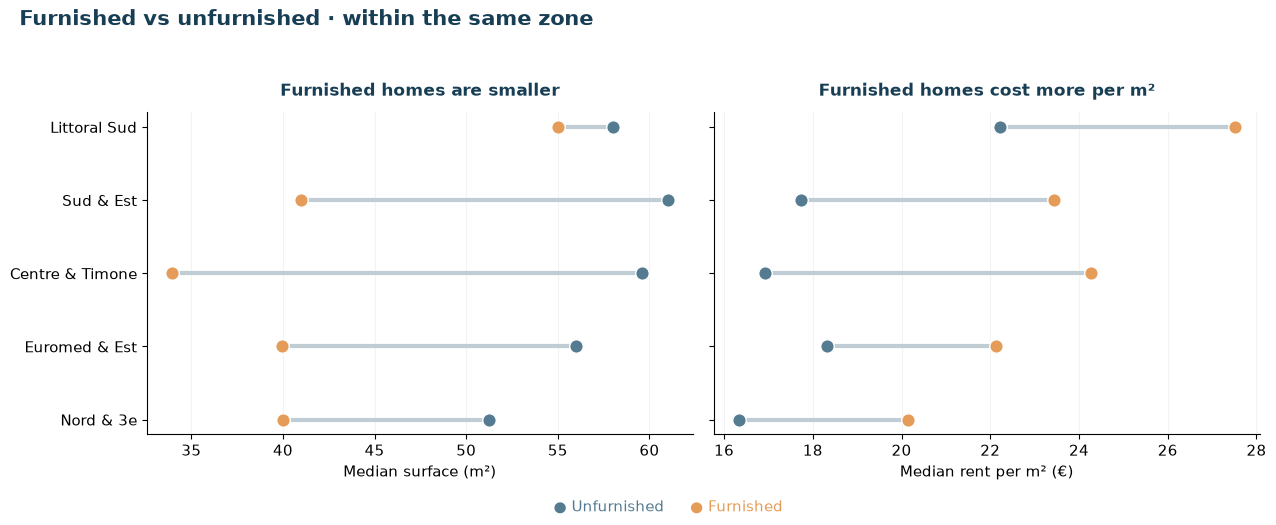

In [10]:
# Keep unknown furnishing status out of both furnished groups.
furn_data = eda.loc[eda['is_furnished_binary'].isin([0,1])].dropna(
    subset=['surface_m2','price_per_m2','urban_zone']).copy()
# Compare medians within the same zone to reduce geographic composition bias.
furn_summary = furn_data.groupby(['urban_zone','is_furnished_binary']).agg(
    median_size=('surface_m2','median'),
    median_price=('price_per_m2','median'), n=('price_per_m2','size'))

fig, axes=plt.subplots(1,2,figsize=(12.9,4.9), sharey=True)
for a,col,title,xlabel in [
    (axes[0],'median_size','Furnished homes are smaller','Median surface (m²)'),
    (axes[1],'median_price','Furnished homes cost more per m²','Median rent per m² (€)')]:
    for i,zone in enumerate(zones):
        x_no = furn_summary.loc[(zone,0.0),col]
        x_yes= furn_summary.loc[(zone,1.0),col]
        a.plot([x_no,x_yes],[i,i],color='#c1cdd4',lw=3,zorder=1)
        a.scatter(x_no,i,c=COLOR_UNFURNISHED,s=95,edgecolors='white',zorder=3)
        a.scatter(x_yes,i,c=COLOR_FURNISHED,s=95,edgecolors='white',zorder=3)
    a.set_yticks(np.arange(len(zones)),zone_names)
    a.grid(axis='x',alpha=.14);a.set_axisbelow(True)
    a.set_title(title,fontsize=12,weight='bold',color='#173e54',pad=12)
    a.set_xlabel(xlabel)
axes[0].invert_yaxis()
fig.suptitle('Furnished vs unfurnished · within the same zone',fontsize=15,
             x=.02,ha='left',y=1.04,color='#173e54',weight='bold')
fig.text(.52,.015,'● Unfurnished',ha='right',color=COLOR_UNFURNISHED,fontsize=11)
fig.text(.54,.015,'● Furnished',ha='left',color=COLOR_FURNISHED,fontsize=11)
fig.tight_layout(rect=[0,.045,1,1])
fig.savefig(CHARTS_DIR / '02_furnished_vs_unfurnished.png', dpi=300, bbox_inches='tight')
plt.show()

<div style="background:#edf8f2;border-left:4px solid #2b9a6c;padding:12px 15px;border-radius:5px;font-size:13px;color:#244838;line-height:1.55;"><strong style="color:#217d56;">Interpretation</strong><p style="margin:7px 0 0;">Furnished listings are smaller and have higher median rents per m² in all five zones. Since small apartments already command higher prices per m², this difference cannot be attributed to furniture alone.</p></div>

<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">PART II · Affordability and moving costs</h2>

### 3 · What can students actually rent on a chosen budget?

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">Choose a monthly budget and furnishing status. For each zone, the **colored part** shows the share of ads under the budget, broken down by apartment type. **Grey** shows the share above the budget. All bars add up to 100% of ads in the selected zone. This is not a real-time availability measure.</div>

In [11]:
# Interactive budget composition: percentages are always relative to all
# adverts in each zone after applying the selected furnishing-status filter.
budget_data = eda.dropna(subset=['price_total_eur','urban_zone','property_type_label']).copy()
budget_data = budget_data.loc[budget_data['price_total_eur'].gt(0) &
    budget_data['urban_zone'].isin(zones) &
    budget_data['property_type_label'].isin(TYPE_ORDER)].copy()

def budget_figure(budget=800, status='All statuses'):
    sub=budget_data.copy()
    if status == 'Furnished':
        sub=sub.loc[sub['is_furnished_binary'].eq(1)]
    elif status == 'Unfurnished':
        sub=sub.loc[sub['is_furnished_binary'].eq(0)]
    # The denominator is all ads in the zone, not just the affordable ones.
    totals=sub.groupby('urban_zone').size().reindex(zones,fill_value=0)
    affordable=sub[sub['price_total_eur']<=budget]
    counts=affordable.groupby(['urban_zone','property_type_label']).size()
    fig=go.Figure()
    for typ in TYPE_ORDER:
        nums=np.array([int(counts.get((z,typ),0)) for z in zones])
        den=totals.to_numpy()
        share=np.divide(100*nums,den,out=np.zeros(5,dtype=float),where=den>0)
        fig.add_trace(go.Bar(
            y=zone_names,x=share,orientation='h',name=typ,
            marker_color=TYPE_COLORS[typ],customdata=np.column_stack([nums,den]),
            hovertemplate=f'<b>%{{y}}</b> · {typ}<br>'
                'Under budget: %{customdata[0]} of %{customdata[1]} ads<br>'
                'Share of zone: %{x:.1f}%<extra></extra>'))
    affordable_counts=affordable.groupby('urban_zone').size().reindex(zones,fill_value=0).to_numpy()
    den=totals.to_numpy()
    affordable_share=np.divide(100*affordable_counts,den,out=np.zeros(5),where=den>0)
    # The gray remainder makes the unaffordable share visible at a glance.
    unavailable=100-affordable_share
    fig.add_trace(go.Bar(y=zone_names,x=unavailable,orientation='h',
        name='Over budget',marker_color='#dbe2e7',
        customdata=np.column_stack([den-affordable_counts,den]),
        hovertemplate='<b>%{y}</b> · Over budget<br>%{customdata[0]} of '
                      '%{customdata[1]} ads<extra></extra>'))
    fig.add_trace(go.Scatter(x=[103]*5,y=zone_names,mode='text',showlegend=False,
        text=[f'{v:.0f}%' if n>0 else 'n/a' for v,n in zip(affordable_share,den)],
        textfont=dict(size=12,color='#173e54'),hoverinfo='skip'))
    fig.update_layout(template='plotly_white',barmode='stack',height=450,
        title=dict(text=f'With €{budget:,} per month, which apartments fit the budget?',
                   font=dict(size=18,color='#173e54')),
        xaxis=dict(range=[0,111],title='Share of ads in each zone (%)',ticksuffix='%',
                   gridcolor='#eef2f5'),
        yaxis=dict(categoryorder='array',categoryarray=zone_names[::-1],title=None),
        legend=dict(orientation='h',y=1.11,x=0),
        margin=dict(l=35,r=20,t=100,b=70),
        annotations=[dict(x=.01,y=-.20,xref='paper',yref='paper',showarrow=False,
           text=f'Included: {len(sub)} ads · Unknown furnishing status remains in “All statuses”',
           font=dict(size=11,color='#687b88'),align='left')])
    return fig

# A live pair of controls in Jupyter; a default chart is shown in environments
# without ipywidgets. A standalone HTML dashboard is also supplied.
if HAS_WIDGETS:
    budget_control=widgets.IntSlider(value=800,min=400,max=2000,step=50,
        description='Budget (€)',continuous_update=False,
        style={'description_width':'initial'},layout=widgets.Layout(width='440px'))
    status_control=widgets.Dropdown(options=['All statuses','Furnished','Unfurnished'],
        description='Furnishing',style={'description_width':'initial'})
    def show_budget(budget,status):
        budget_figure(budget,status).show()
    budget_view=widgets.interactive_output(show_budget,
        {'budget':budget_control,'status':status_control})
    display(widgets.HBox([budget_control,status_control]),budget_view)
else:
    budget_figure(800,'All statuses').show()

Output()

<div style="background:#edf8f2;border-left:4px solid #2b9a6c;padding:12px 15px;border-radius:5px;font-size:13px;color:#244838;line-height:1.55;"><strong style="color:#217d56;">Interpretation</strong><p style="margin:7px 0 0;">The colored mix answers two questions at once: what fraction of each zone’s listings fits the budget, and which apartment types make up that affordable fraction. Changing the budget can change the mix. A large grey section means fewer matching listings in this collected sample.</p></div>

### 4 · How much money must tenants pay upfront?

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">Upfront payment includes the costs captured in the cleaning dataset. To compare unlike monthly rents fairly, we divide the initial amount by monthly rent. A value of 3 means an initial payment equivalent to three months of rent. We use only listings with complete relevant information.</div>

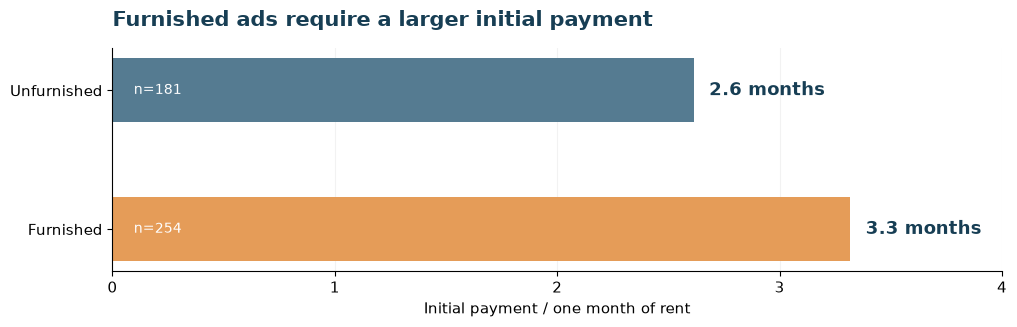

Upfront-cost cases with known furnishing: 435 of 909 ads.


In [12]:
finance=eda.dropna(subset=['price_total_eur','upfront_move_in_cost_eur',
                                'is_furnished_binary']).copy()
finance=finance.loc[(finance['price_total_eur']>0)&
    (finance['upfront_move_in_cost_eur']>=0)&
    (finance['is_furnished_binary'].isin([0,1]))].copy()
# Express the initial payment in equivalent months of rent for fair comparison.
finance['months']=finance['upfront_move_in_cost_eur']/finance['price_total_eur']
move=finance.groupby('is_furnished_binary')['months'].agg(['count','median'])
values=[move.loc[0.0,'median'],move.loc[1.0,'median']]
ns=[int(move.loc[0.0,'count']),int(move.loc[1.0,'count'])]
fig,ax=plt.subplots(figsize=(10.3,3.4))
labels=['Unfurnished','Furnished']; colors=[COLOR_UNFURNISHED,COLOR_FURNISHED]
for i,(val,c,n) in enumerate(zip(values,colors,ns)):
    ax.barh(i,val,height=.46,color=c)
    ax.text(val+.07,i,f'{val:.1f} months',va='center',weight='bold',
            fontsize=13,color='#173e54')
    ax.text(.06,i,f'  n={n}',va='center',color='white',fontsize=10,weight='medium')
ax.set_yticks([0,1],labels);ax.invert_yaxis()
ax.set_xlim(0,4);ax.set_xticks([0,1,2,3,4]);ax.set_xlabel('Initial payment / one month of rent')
ax.set_title('Furnished ads require a larger initial payment',loc='left',
             fontsize=15,color='#173e54',weight='bold',pad=16)
ax.grid(axis='x',alpha=.16);ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(CHARTS_DIR / '03_upfront_costs.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Upfront-cost cases with known furnishing: {len(finance)} of {len(eda)} ads.')

<div style="background:#edf8f2;border-left:4px solid #2b9a6c;padding:12px 15px;border-radius:5px;font-size:13px;color:#244838;line-height:1.55;"><strong style="color:#217d56;">Interpretation</strong><p style="margin:7px 0 0;">For listings with reported upfront costs and known furnishing status, the typical initial payment is about 3.2 months of rent for furnished homes versus about 2.6 months for unfurnished homes. Many listings lack complete cost information, so this describes the complete-case subset only.</p></div>

<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">PART III · Explaining price differences</h2>

### 5 · Does location still matter for the same apartment profile?

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">We reuse the ANCOVA model from the EDA, adjusting for surface, apartment type, furnishing and DPE. The first mode compares **estimated rents** for one fixed profile across the five zones. The second mode shows **how the percentage gap between two chosen zones changes with surface**. These are model estimates, not observed identical flats.</div>

In [13]:
# Exactly the ANCOVA specification used in the EDA.
columns=['price_total_eur','surface_m2','urban_zone',
         'property_type_label','is_furnished_binary','dpe_class']
comparables=eda.dropna(subset=columns).copy()
comparables=comparables.loc[(comparables['price_total_eur']>0)&
    (comparables['surface_m2']>0)].copy()
reference_surface=comparables['surface_m2'].median()
comparables['surface_centered']=np.log(comparables['surface_m2']/reference_surface)
ancova=smf.ols('np.log(price_total_eur) ~ surface_centered * C(urban_zone)'
               ' + C(property_type_label) + C(is_furnished_binary) + C(dpe_class)',
               data=comparables).fit(cov_type='HC3')

PROFILES=[
    ('Studio / T1 · 23 m² · furnished · DPE C','Studio / T1',23,1,'C'),
    ('T2 · 40 m² · furnished · DPE D','T2',40,1,'D'),
    ('T2 · 40 m² · unfurnished · DPE C','T2',40,0,'C'),
    ('T3 · 65 m² · unfurnished · DPE C','T3',65,0,'C'),
    ('T4+ · 90 m² · furnished · DPE D','T4+',90,1,'D'),
]

# Build comparable model inputs: only zone and/or surface varies between predictions.
def profile_frame(profile,zone_list,surfaces):
    _label,typ,_size,furn,dpe=profile
    sample=pd.DataFrame({'urban_zone':zone_list,'property_type_label':typ,
        'is_furnished_binary':float(furn),'dpe_class':dpe,'surface_m2':surfaces})
    sample['surface_centered']=np.log(sample['surface_m2']/reference_surface)
    return sample

def model_rent_figure(profile_idx=0):
    p=PROFILES[profile_idx]
    test=profile_frame(p,zones,[p[2]]*len(zones))
    # ANCOVA predicts log-rent: exponentiate to display results in euros.
    pred=ancova.get_prediction(test).summary_frame(alpha=.05)
    estimate=np.exp(pred['mean'].to_numpy())
    lo=np.exp(pred['mean_ci_lower'].to_numpy())
    hi=np.exp(pred['mean_ci_upper'].to_numpy())
    support=[]
    for z in zones:
        count=len(comparables.loc[(comparables['urban_zone']==z)&
            (comparables['property_type_label']==p[1])&
            (comparables['is_furnished_binary']==p[3])&
            (comparables['dpe_class']==p[4])])
        support.append(count)
    fig=go.Figure(go.Bar(y=zone_names,x=estimate,orientation='h',
        marker_color=zone_colors,
        text=[f'€{n:,.0f}' for n in estimate],textposition='outside',
        cliponaxis=False,
        customdata=np.column_stack([lo,hi,support]),
        hovertemplate='<b>%{y}</b><br>Adjusted rent: €%{x:,.0f}<br>'
            '95% CI of estimated mean: €%{customdata[0]:,.0f} – €%{customdata[1]:,.0f}<br>'
            'Ads with exact type / furnishing / DPE: %{customdata[2]:.0f}'
            '<extra></extra>'))
    fig.update_layout(template='plotly_white',height=460,
        title=dict(text='Same apartment profile → different estimated rents',
                   font=dict(size=18,color='#173e54')),
        xaxis=dict(title='Estimated monthly rent (€)',rangemode='tozero',
                   range=[0,float(max(hi)*1.22)],gridcolor='#eaf0f4'),
        yaxis=dict(categoryorder='array',categoryarray=zone_names[::-1]),
        margin=dict(l=45,r=35,t=78,b=70),showlegend=False,
        annotations=[dict(x=.01,y=-.20,xref='paper',yref='paper',showarrow=False,
                          text='Model estimate · 95% confidence intervals and group sizes on hover',
                          font=dict(color='#617685',size=11))])
    return fig

def model_gap_figure(profile_idx=0,zone_a=0,zone_b=4):
    p=PROFILES[profile_idx]
    if zone_a==zone_b:
        raise ValueError('Choose two different zones.')
    typical=comparables.loc[comparables['property_type_label'].eq(p[1]),'surface_m2']
    low_q,high_q=typical.quantile([.10,.90])
    sizes=np.linspace(max(10,float(low_q)),float(high_q),45)
    a=profile_frame(p,[zones[zone_a]]*len(sizes),sizes)
    b=profile_frame(p,[zones[zone_b]]*len(sizes),sizes)
    design=ancova.model.data.design_info
    Xa=np.asarray(build_design_matrices([design],a,return_type='dataframe')[0])
    Xb=np.asarray(build_design_matrices([design],b,return_type='dataframe')[0])
    # Contrast design matrices to estimate the percentage difference between zones.
    difference=Xa-Xb
    log_ratio=difference@ancova.params.to_numpy()
    covariance=ancova.cov_params().to_numpy()
    se=np.sqrt(np.maximum(np.einsum('ij,jk,ik->i',difference,covariance,difference),0))
    z=norm.ppf(.975)
    gap=100*np.expm1(log_ratio)
    gap_lo=100*np.expm1(log_ratio-z*se)
    gap_hi=100*np.expm1(log_ratio+z*se)
    fig=go.Figure()
    # The shaded band is the robust 95% CI for the adjusted zone contrast.
    fig.add_trace(go.Scatter(x=sizes,y=gap_hi,mode='lines',showlegend=False,
        line=dict(width=0),hoverinfo='skip'))
    fig.add_trace(go.Scatter(x=sizes,y=gap_lo,mode='lines',fill='tonexty',
        fillcolor='rgba(44,121,165,.15)',line=dict(width=0),showlegend=False,hoverinfo='skip'))
    fig.add_trace(go.Scatter(x=sizes,y=gap,mode='lines',
        line=dict(color='#2c79a5',width=3.2),
        customdata=np.column_stack([gap_lo,gap_hi]),
        hovertemplate='Surface %{x:.0f} m²<br>Adjusted rent gap: %{y:+.1f}%<br>'
             '95% CI: %{customdata[0]:+.1f}% to %{customdata[1]:+.1f}%<extra></extra>',
        showlegend=False))
    fig.add_hline(y=0,line_dash='dash',line_color='#777e86')
    fig.update_layout(template='plotly_white',height=460,
        title=dict(text=f'Price gap: {zone_names[zone_a]} vs {zone_names[zone_b]}',
                   font=dict(size=18,color='#173e54')),
        xaxis=dict(title='Surface (m²)',gridcolor='#eaf0f4'),
        yaxis=dict(title='Adjusted rent difference (%)',ticksuffix='%',gridcolor='#eaf0f4'),
        margin=dict(l=70,r=35,t=78,b=80),
        annotations=[dict(x=.01,y=-.20,xref='paper',yref='paper',showarrow=False,
            text='Positive = first zone is more expensive · Shaded area = 95% CI',
            font=dict(color='#617685',size=11))])
    return fig

if HAS_WIDGETS:
    p_select=widgets.Dropdown(options=[(p[0],i) for i,p in enumerate(PROFILES)],
        description='Apartment profile',style={'description_width':'initial'},
        layout=widgets.Layout(width='445px'))
    mode_select=widgets.ToggleButtons(options=['Compare 5 zones','Gap vs surface'],
        description='View',style={'description_width':'initial'})
    zone_a=widgets.Dropdown(options=[(name,i) for i,name in enumerate(zone_names)],
        value=0,description='First zone',style={'description_width':'initial'})
    zone_b=widgets.Dropdown(options=[(name,i) for i,name in enumerate(zone_names)],
        value=4,description='Second zone',style={'description_width':'initial'})
    def show_ancova(profile,mode,first,second):
        if mode=='Compare 5 zones':
            model_rent_figure(profile).show()
        elif first!=second:
            model_gap_figure(profile,first,second).show()
        else:
            print('Select two different geographical zones.')
    model_view=widgets.interactive_output(show_ancova,
        {'profile':p_select,'mode':mode_select,'first':zone_a,'second':zone_b})
    display(widgets.VBox([p_select,mode_select,
              widgets.HBox([zone_a,zone_b])]),model_view)
else:
    model_rent_figure(0).show()

print(f'ANCOVA uses {len(comparables)} complete cases; '
      f'adjusted R² = {ancova.rsquared_adj:.3f}.')

Output()

ANCOVA uses 578 complete cases; adjusted R² = 0.837.


<div style="background:#edf8f2;border-left:4px solid #2b9a6c;padding:12px 15px;border-radius:5px;font-size:13px;color:#244838;line-height:1.55;"><strong style="color:#217d56;">Interpretation</strong><p style="margin:7px 0 0;">The same modeled apartment profile has different estimated rents across zones. The size of the geographical gap can also change with surface area; this was a significant interaction in the EDA. These bars and curves are adjusted model estimates, not observed listings of identical properties. Some exact profile/zone combinations are rare, so confidence intervals matter.</p></div>

<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">Final notes · What the charts do and do not establish</h2>

<div style="background:#f2f6f8;border-left:4px solid #9bacb6;padding:13px 15px;border-radius:5px;color:#314957;font-size:13px;line-height:1.6;">
Each graphic has a distinct purpose: <b>size and price</b>; <b>furnished vs unfurnished</b>; <b>housing mix within a budget</b>; <b>upfront costs</b>; <b>adjusted geographical differences</b>; and <b>declared amenities</b>. No map, arrondissement dot plot, forest plot or repeated statistical summary tables are included.<br><br>
The figures describe a non-random sample of online advertisements. They are not estimates of housing availability for Marseille as a whole. Filtering reduces sample sizes. Missing amenity and furnishing fields are kept distinct from confirmed absence. ANCOVA/amenity model associations do not prove causation.
</div>

<h2 style="color:#163e55;border-bottom:2px solid #e4edf2;padding:0 0 9px;margin-top:24px;font-size:21px;">Export · Save and download the charts</h2>

<div style="background:#edf6fc;border-left:4px solid #3889ba;padding:12px 15px;border-radius:5px;font-size:13px;color:#29465c;line-height:1.55;">The three static figures are saved as high-resolution PNGs when their cells run. The interactive Plotly views are saved as standalone HTML files. This final cell packages everything into <code>marseille_charts.zip</code> and gives you a download link. In exported HTML, Plotly hover and zoom work, but Jupyter widget controls stay in the notebook; the HTML files show the default selections.</div>

In [14]:
from pathlib import Path

# Create the charts directory if it does not exist.
CHARTS_DIR = Path("charts")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

# Save interactive Plotly charts as standalone HTML files.
interactive_exports = {
    "04_budget_800_eur.html": budget_figure(800, "All statuses"),
    "05_ancova_same_profile.html": model_rent_figure(0),
    "06_ancova_gap_by_surface.html": model_gap_figure(0, 0, 4),
}

for filename, figure in interactive_exports.items():
    figure.write_html(
        CHARTS_DIR / filename,
        include_plotlyjs=True,
        full_html=True
    )

# Static PNG charts are saved by the Matplotlib cells above.
expected_png = [
    "01_surface_vs_rent.png",
    "02_furnished_vs_unfurnished.png",
    "03_upfront_costs.png",
]

missing_png = [
    name for name in expected_png
    if not (CHARTS_DIR / name).is_file()
]

if missing_png:
    print("Run the static chart cells to generate:", ", ".join(missing_png))

# Display the location and contents of the directory.
print(f"Charts saved in: {CHARTS_DIR.resolve()}")

for chart_path in sorted(CHARTS_DIR.iterdir()):
    if chart_path.is_file():
        print(" -", chart_path.name)

Charts saved in: C:\Users\romay\OneDrive\BOUKRIF_Romayssa_CHAHINE_Rami_G5\BOUKRIF_Romayssa_CHAHINE_Rami_G5_Code\charts
 - 01_surface_vs_rent.png
 - 02_furnished_vs_unfurnished.png
 - 03_upfront_costs.png
 - 04_budget_800_eur.html
 - 05_ancova_same_profile.html
 - 06_ancova_gap_by_surface.html
